# Backtest de Factor Investing — IQF, Grupo 4

Simulação da estratégia escolhida de out/2016 a out/2026, com rebalanceamento trimestral, comparada com o Ibovespa e o CDI, já descontados os custos.

O notebook traz o código completo e já está executado: os resultados aparecem no fim, sem precisar rodar nada. Para rodar de novo, é necessário usar os arquivos do Economatica em `data/` e instalar as dependências em `requirements.txt` (veja o README).

Mas para fim dessa entrega só existirá esse notebook jupyter

## Estratégia

A carteira tem 20 ações, com 5% (pesos iguais por ação) em cada uma, divididas em duas partes:

| Carteira | Peso | Filtros, em ordem |
|---|---|---|
| Defensiva | 70% (14 ações) | P/L < 20 → ROIC > 10%, 30 melhores → 14 melhores na nota 60% downside deviation (5 anos) + 40% momentum (12 meses) |
| Agressiva | 30% (6 ações) | Valor de mercado < R$ 2 bi → beta > 1 → receita +52,09% em 3 anos (15% a.a.) → 6 melhores em momentum (6 meses) |

Vaga que nenhuma ação preenche fica aplicada no CDI.


## 1. Parâmetros

In [1]:
DATA_INICIO = "2016-10-29"
DATA_FIM = "2026-10-29"
MESES_REBAL = 3
CUSTO = 0.001  # 0,1% descontado no primeiro dia de cada rebalanceamento
DEFASAGEM_DIAS = 90  # espera até o balanço ser publicado
VOLUME_MINIMO = 1_000  # R$ mil por dia: mediana da janela de liquidez
MESES_LIQUIDEZ = 3

## 2. Base de dados

Lê as planilhas do Economatica, define o universo de ações líquidas e entrega o último balanço já publicado em cada data.

In [2]:
import pandas as pd


class BaseDados:
    """Lê os arquivos do Economatica: data no índice, uma coluna por ação, NaN onde falta dado."""

    def __init__(self, pasta, defasagem_dias, volume_minimo, meses_liquidez):
        self.pasta = pasta
        self.defasagem = pd.Timedelta(days=defasagem_dias)
        self.volume_minimo = volume_minimo
        self.meses_liquidez = meses_liquidez

        # Dia sem negócio mantém o preço anterior, para o retorno não sumir da conta.
        self.precos = self._acoes("fechamento").ffill()
        self.retornos = self.precos.pct_change(fill_method=None)
        self.roic = self._acoes("roic")
        self.lucro = self._acoes("lucro_liquido")
        self.receita = self._acoes("receita_liquida")
        self.valor_mercado = self._acoes("valor_mercado")
        self.volume = self._acoes("volume")
        self.retorno_ibov = self._retorno_indice("ibovespa")
        self.retorno_cdi = self._retorno_indice("CDI")

    def _ler(self, nome):
        bruto = pd.read_excel(f"{self.pasta}/{nome}.xlsx", header=None, engine="calamine")
        linha = bruto.index[bruto[0] == "Data"][0]  # o cabeçalho muda de linha entre os arquivos
        tabela = bruto.loc[linha + 1:].set_index(0)
        tabela.index = pd.to_datetime(tabela.index).rename("Data")
        tabela.columns = bruto.loc[linha, 1:].str.split("\n").str[-1].str.strip()
        return tabela.apply(pd.to_numeric, errors="coerce").sort_index()

    def _acoes(self, nome):
        # O filtro descarta a coluna sem ticker que o Economatica coloca depois da data.
        return self._ler(nome).filter(regex=r"^[A-Z0-9]+$").dropna(how="all")

    def _retorno_indice(self, nome):
        indice = self._ler(nome).iloc[:, 0].reindex(self.precos.index).ffill()
        return indice.pct_change(fill_method=None)

    def ultimo_pregao(self, data):
        return self.precos.loc[:data].index[-1]

    def universo(self, data):
        """Classe mais negociada de cada empresa, entre as ações líquidas na data."""
        inicio = data - pd.DateOffset(months=self.meses_liquidez)
        volume = self.volume.loc[inicio:data].fillna(0).median()
        liquidas = volume[volume >= self.volume_minimo]
        return liquidas.groupby(lambda ticker: ticker[:4]).idxmax().tolist()

    def ultimo_balanco(self, tabela, data):
        """Último balanço já publicado: a defasagem evita usar informação do futuro."""
        corte = data - self.defasagem
        return tabela.loc[corte - pd.DateOffset(months=6):corte].ffill().iloc[-1]

## 3. Estratégias

Cada carteira é uma classe com o método `selecionar(data)`, que devolve os tickers escolhidos usando só informação até aquela data.

In [3]:
from abc import ABC, abstractmethod

import pandas as pd


class Estrategia(ABC):
    """Regra de seleção de uma carteira. Em cada data, só usa informação até aquela data."""

    peso = None
    n_acoes = None

    def __init__(self, base):
        self.base = base

    @abstractmethod
    def selecionar(self, data):
        """Devolve a lista de tickers escolhidos na data."""

    def _momentum(self, data, meses):
        janela = self.base.precos.loc[data - pd.DateOffset(months=meses):data]
        return janela.iloc[-1] / janela.iloc[0] - 1


class Defensiva(Estrategia):
    """P/L < 20 → ROIC > 10% (30 melhores) → 14 melhores em low vol (60%) e momentum (40%)."""

    peso = 0.70
    n_acoes = 14
    pl_maximo = 20
    roic_minimo = 10
    n_melhores_roic = 30
    peso_low_vol = 0.60
    anos_low_vol = 5
    meses_momentum = 12

    def selecionar(self, data):
        valor_mercado = self.base.valor_mercado.loc[:data].iloc[-1]
        lucro = self.base.ultimo_balanco(self.base.lucro, data)
        pl = (valor_mercado / lucro)[self.base.universo(data)]
        baratas = pl[(pl > 0) & (pl < self.pl_maximo)].index

        roic = self.base.ultimo_balanco(self.base.roic, data)[baratas]
        melhores = roic[roic > self.roic_minimo].nlargest(self.n_melhores_roic).index

        downside = self._downside_deviation(data)[melhores]
        momentum = self._momentum(data, self.meses_momentum)[melhores]
        nota = (self.peso_low_vol * downside.rank()
                + (1 - self.peso_low_vol) * momentum.rank(ascending=False))
        # dropna: com poucas ações, o nsmallest manteria quem não tem histórico.
        return nota.dropna().nsmallest(self.n_acoes).index.tolist()

    def _downside_deviation(self, data):
        inicio = data - pd.DateOffset(years=self.anos_low_vol)
        negativos = self.base.retornos.loc[inicio:data].clip(upper=0)
        return (negativos ** 2).mean() ** 0.5


class Agressiva(Estrategia):
    """Valor de mercado < R$ 2 bi → beta > 1 → receita +52,09% em 3 anos → 6 melhores em momentum."""

    peso = 0.30
    n_acoes = 6
    valor_mercado_maximo = 2_000_000  # R$ mil
    beta_minimo = 1
    anos_beta = 1
    crescimento_minimo = 0.5209
    anos_crescimento = 3
    meses_momentum = 6

    def selecionar(self, data):
        valor_mercado = self.base.valor_mercado.loc[:data].iloc[-1][self.base.universo(data)]
        small_caps = valor_mercado[valor_mercado < self.valor_mercado_maximo].index

        beta = self._beta(data, small_caps)
        volateis = beta[beta > self.beta_minimo].index

        crescimento = self._crescimento_receita(data)[volateis]
        crescem = crescimento[crescimento > self.crescimento_minimo].index

        momentum = self._momentum(data, self.meses_momentum)[crescem]
        # dropna: com poucas ações, o nlargest manteria quem não tem histórico.
        return momentum.dropna().nlargest(self.n_acoes).index.tolist()

    def _beta(self, data, tickers):
        inicio = data - pd.DateOffset(years=self.anos_beta)
        acoes = self.base.retornos.loc[inicio:data, tickers]
        ibov = self.base.retorno_ibov.loc[inicio:data]
        return acoes.apply(lambda retorno: retorno.cov(ibov)) / ibov.var()

    def _crescimento_receita(self, data):
        antes = data - pd.DateOffset(years=self.anos_crescimento)
        receita_antes = self.base.ultimo_balanco(self.base.receita, antes)
        receita = self.base.ultimo_balanco(self.base.receita, data)
        return receita / receita_antes.where(receita_antes > 0) - 1

## 4. Loop do backtest

In [4]:
import pandas as pd


class Backtest:
    """Loop da Aula 2: em cada rebalanceamento, escolhe as ações e mede o retorno até o próximo."""

    def __init__(self, base, estrategias, data_inicio, data_fim, meses_rebal, custo):
        self.base = base
        self.estrategias = estrategias
        self.data_inicio = pd.Timestamp(data_inicio)
        self.data_fim = pd.Timestamp(data_fim)
        self.rebal_time = pd.DateOffset(months=meses_rebal)
        self.custo = custo

    def rodar(self):
        retornos, carteiras = [], []
        data_atual = self.data_inicio
        while data_atual + self.rebal_time <= self.data_fim:
            data_prox_rebal = data_atual + self.rebal_time
            pregao = self.base.ultimo_pregao(data_atual)
            selecao = {estrategia: estrategia.selecionar(pregao) for estrategia in self.estrategias}

            retornos.append(self._retorno_periodo(selecao, pregao, self.base.ultimo_pregao(data_prox_rebal)))
            carteiras += [{"data": pregao.date(), "carteira": type(estrategia).__name__, "n_acoes": len(tickers),
                           "tickers": " ".join(tickers)} for estrategia, tickers in selecao.items()]
            data_atual = data_prox_rebal
        return pd.concat(retornos).rename("Estrategia"), pd.DataFrame(carteiras)

    def _retorno_periodo(self, selecao, pregao, prox_pregao):
        acoes = self.base.retornos.loc[pregao:prox_pregao].iloc[1:]
        cdi = self.base.retorno_cdi.loc[acoes.index]
        retorno = 0
        for estrategia, tickers in selecao.items():
            # Cada vaga sem ação que passe nos filtros fica aplicada no CDI.
            vagas_vazias = estrategia.n_acoes - len(tickers)
            retorno_carteira = (acoes[tickers].sum(axis=1) + vagas_vazias * cdi) / estrategia.n_acoes
            retorno = retorno + estrategia.peso * retorno_carteira
        retorno.iloc[0] -= self.custo
        return retorno

## 5. Relatório

In [5]:
import contextlib
from pathlib import Path

import matplotlib

matplotlib.use("Agg")  # salva os gráficos sem abrir janela

import quantstats as qs

FONTE = "DejaVu Sans"


class Relatorio:
    """Salva os retornos, as carteiras, as métricas e os gráficos da Aula 2."""

    def __init__(self, pasta):
        self.pasta = Path(pasta)
        self.pasta.mkdir(exist_ok=True)

    def salvar(self, retornos, carteiras, retorno_ibov, retorno_cdi):
        ibov = retorno_ibov.loc[retornos.index].rename("Ibovespa")
        cdi = retorno_cdi.loc[retornos.index]

        retornos.to_csv(self.pasta / "retornos_diarios.csv")
        carteiras.to_csv(self.pasta / "carteiras.csv", index=False)
        self._salvar_metricas(retornos, ibov, cdi)

        qs.plots.returns(retornos, ibov, fontname=FONTE, show=False,
                         savefig=self.pasta / "retorno_acumulado.png")
        qs.plots.drawdown(retornos, fontname=FONTE, show=False,
                          savefig=self.pasta / "underwater.png")
        qs.plots.drawdowns_periods(retornos, title="Estratégia", fontname=FONTE, show=False,
                                   savefig=self.pasta / "piores_drawdowns.png")

    def _salvar_metricas(self, retornos, ibov, cdi):
        cdi_anual = qs.stats.cagr(cdi)

        with open(self.pasta / "metricas.txt", "w") as arquivo, contextlib.redirect_stdout(arquivo):
            print(f"CDI no período: retorno acumulado {(1 + cdi).prod() - 1:.2%}, CAGR {cdi_anual:.2%}\n")
            qs.reports.metrics(retornos, benchmark=ibov, rf=cdi_anual, mode="full", display=True,
                               strategy_title="Estratégia", benchmark_title="Ibovespa")

## 6. Execução

Leva cerca de 1 minuto, quase todo gasto lendo as planilhas.

In [6]:
base = BaseDados("data", DEFASAGEM_DIAS, VOLUME_MINIMO, MESES_LIQUIDEZ)
backtest = Backtest(base, [Defensiva(base), Agressiva(base)], DATA_INICIO, DATA_FIM, MESES_REBAL, CUSTO)
retornos, carteiras = backtest.rodar()
Relatorio("output").salvar(retornos, carteiras, base.retorno_ibov, base.retorno_cdi)

## 7. Resultados

### Métricas

Estratégia contra o Ibovespa. O Sharpe desconta o CDI do período, mostrado na primeira linha.

In [7]:
print(open("output/metricas.txt").read())

CDI no período: retorno acumulado 144.44%, CAGR 9.50%


Parameter       Value
--------------  --------
Benchmark       Ibovespa
Risk-Free Rate  9.5%
Periods/Year    252
Compounded      Yes
Match Dates     Yes


                           Ibovespa    Estratégia
-------------------------  ----------  ------------
Start Period               2016-10-31  2016-10-31
End Period                 2026-10-29  2026-10-29
Risk-Free Rate             9.5%        9.5%
Time in Market             100.0%      100.0%

Cumulative Return          163.09%     86.13%
CAGR﹪                     10.32%      6.51%

Sharpe                     0.15        -0.02
Prob. Sharpe Ratio         67.99%      47.06%
Smart Sharpe               0.15        -0.02
Sortino                    0.2         -0.03
Smart Sortino              0.2         -0.03
Sortino/√2                 0.14        -0.02
Smart Sortino/√2           0.14        -0.02
Omega                      1.03        1.0

Max Drawdown               -46.82%     -36.43

### Retorno acumulado

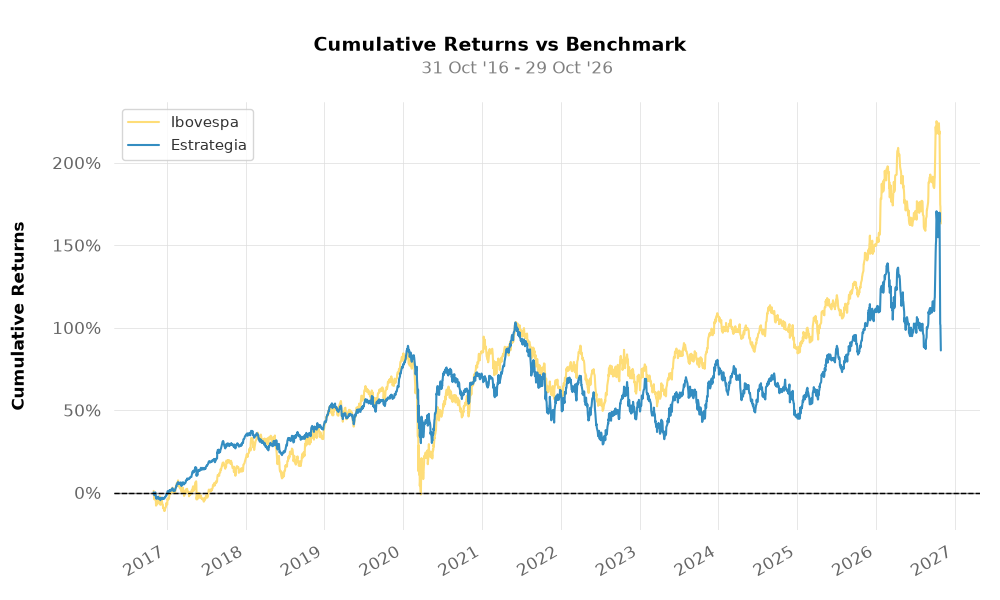

In [8]:
from IPython.display import Image, display

display(Image("output/retorno_acumulado.png"))

### Underwater

Queda em relação ao último topo.

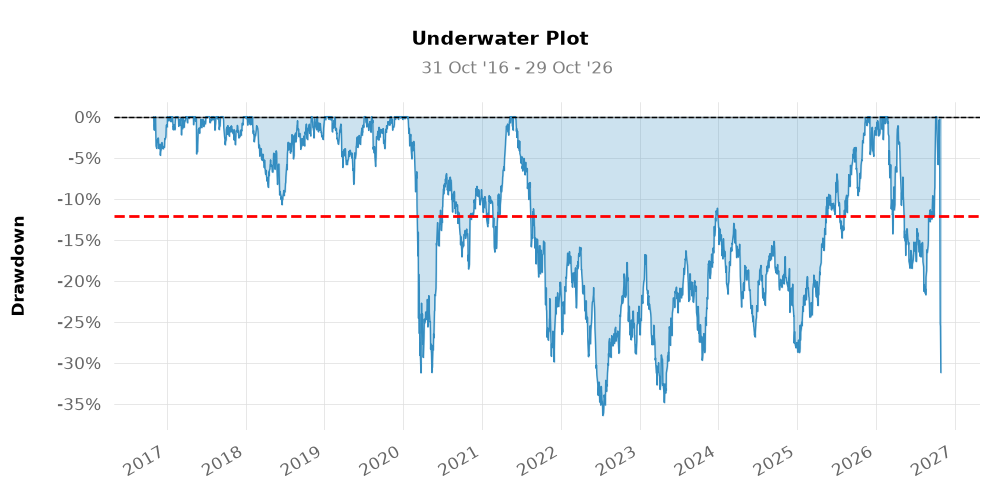

In [9]:
display(Image("output/underwater.png"))

### Piores drawdowns

Os 5 piores períodos de queda.

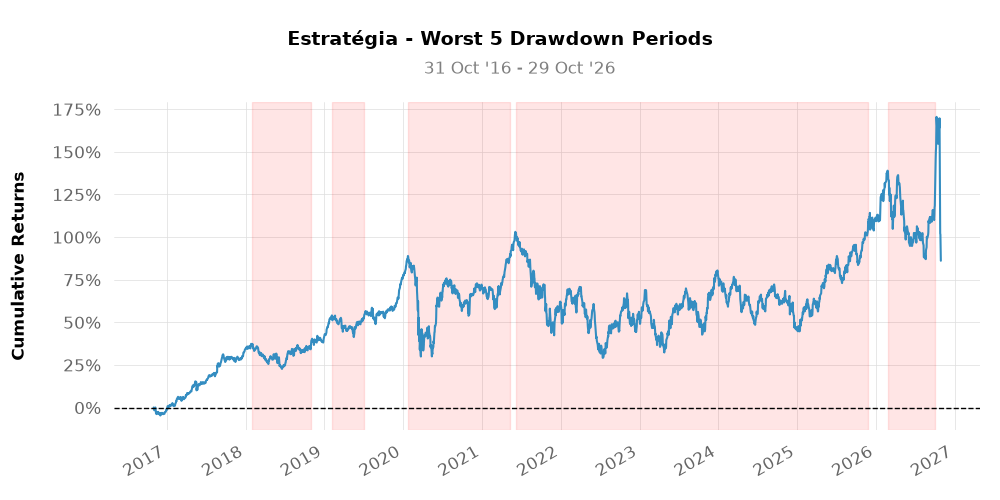

In [10]:
display(Image("output/piores_drawdowns.png"))

### Carteiras

Ações escolhidas em cada rebalanceamento.

In [11]:
with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(carteiras)

,data,carteira,n_acoes,tickers
0,2016-10-28,Defensiva,11,CGAS5 EGIE3 ITSA4 WIZC3 CVCB3 TAEE11 GRND3 ALPA4 SEER3 BRKM5 QUAL3
1,2016-10-28,Agressiva,0,
2,2017-01-27,Defensiva,14,CGAS5 ITSA4 TAEE11 RENT3 EGIE3 CVCB3 GRND3 WIZC3 ALPA4 ISAE4 QUAL3 SEER3 BRKM5 BEEF3
3,2017-01-27,Agressiva,0,
4,2017-04-28,Defensiva,11,CGAS5 GRND3 ALPA4 TAEE11 EGIE3 ITSA4 QUAL3 SEER3 PRIO3 BEEF3 ISAE4
5,2017-04-28,Agressiva,0,
6,2017-07-28,Defensiva,13,GRND3 MDIA3 CGAS5 ALPA4 EGIE3 ITSA4 WIZC3 BEEF3 SEER3 ISAE4 MOTV3 NATU3 AXIA3
7,2017-07-28,Agressiva,0,
8,2017-10-27,Defensiva,11,ALPA4 CGAS5 GRND3 EGIE3 ISAE4 MDIA3 YDUQ3 MOTV3 PRIO3 WIZC3 SEER3
9,2017-10-27,Agressiva,0,


### Retornos diários

In [12]:
retornos

Data
2016-10-31    0.000399
2016-11-01   -0.009760
2016-11-03   -0.006784
2016-11-04    0.005525
2016-11-07    0.009715
                ...   
2026-10-23    0.021062
2026-10-26   -0.250425
2026-10-27   -0.003258
2026-10-28   -0.041461
2026-10-29   -0.036193
Name: Estrategia, Length: 2483, dtype: float64